In [16]:
%pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 4.4 MB/s eta 0:01:19
   ---------------------------------------- 2.4/351.2 MB 7.7 MB/s eta 0:00:46
    --------------------------------------- 4.5/351.2 MB 9.1 MB/s eta 0:00:39
    --------------------------------------- 7.3/351.2 MB 10.4 MB/s eta 0:00:34
   - -------------------------------------- 10.5/351.2 MB 11.6 MB/s eta 0:00:30
   - -------------------------------------- 13.9/351.2 MB 12.4 MB/s eta 0:00:28
   - -------------------------------------- 17.0/351.2 MB 12.8 MB/s eta 0:00:27
   -- ------------------------------------- 20.7/351.2 MB 13.4 MB/s eta 0:00:25
   -- ------------------------------------- 24.4/351.2 MB 14.0 MB/s eta 0:00:24
   --- ------------------------------------ 28.0/351.2 MB 14.4 MB/s eta 0:00:23
   --- ------------------------------------ 31.5/351.2 MB 14.7 MB/s eta 0:00:22
   --- ------------------------------------ 34.1/351.2 M

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [1]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import collections
import time
import json
import random
from PIL import Image
from IPython.display import display

In [2]:
devices=tf.config.experimental.list_physical_devices("GPU")
for device in devices:
    tf.config.experimental.set_memory_growth(device,enable=True)

In [3]:
annotation_folder='./Downloads/Flickr8k_text/'
image_folder="./Downloads/Flickr8k_Dataset/Flickr8k_Dataset/"

In [4]:
annotation_file=os.path.join(annotation_folder,"Flickr8k.token.txt")
with open(annotation_file,"r") as file:
    annotations=file.read()
    file.close()
annotations.split("\n")[1]

'1000268201_693b08cb0e.jpg#1\tA girl going into a wooden building .'

In [5]:
image_path_to_caption=collections.defaultdict(list)
for line in annotations.split('\n'):
    image_name=line.split("#")[0]
    caption=line.split("\t")[-1]
    caption=f"<start> {caption} <end>"
    image_path=os.path.join(image_folder,image_name)
    if image_path.endswith(".jpg"):
        image_path_to_caption[image_path].append(caption)

In [6]:
image_path_to_caption[os.path.join(image_folder,"1003163366_44323f5815.jpg")]

['<start> A man lays on a bench while his dog sits by him . <end>',
 '<start> A man lays on the bench to which a white dog is also tied . <end>',
 '<start> a man sleeping on a bench outside with a white and black dog sitting next to him . <end>',
 '<start> A shirtless man lies on a park bench with his dog . <end>',
 '<start> man laying on bench holding leash of dog sitting on ground <end>']

In [7]:
train_image_paths=list(image_path_to_caption.keys())
random.shuffle(train_image_paths)
print(len(train_image_paths))

8091


<start> A brown dog swimming in the water with a tennis ball in his mouth . <end>


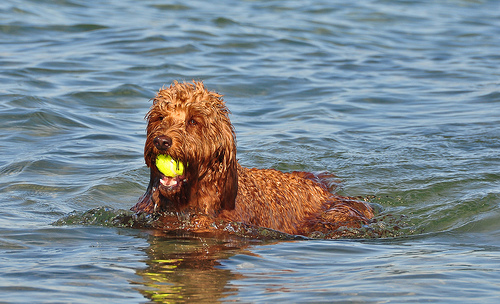

In [126]:
train_captions = []
image_name_vector = []
downloads = os.path.expanduser("~/Downloads")
image_files = {}

for root, dirs, files in os.walk(downloads):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files[file] = os.path.join(root, file)
for image_path in train_image_paths:
    caption_list = image_path_to_caption[image_path]
    train_captions.extend(caption_list)

    filename = os.path.basename(image_path)
    actual_path = image_files.get(filename, image_path)

    image_name_vector.extend([actual_path] * len(caption_list))
print(train_captions[0])
display(Image.open(image_name_vector[0]))

In [9]:
def load_image(image_path):
    image=tf.io.read_file(image_path)
    image=tf.image.decode_jpeg(image,channels=3)
    image=tf.image.resize(image,(299,299))
    image=tf.keras.applications.inception_v3.preprocess_input(image)
    return image, image_path

In [10]:
image_model=tf.keras.applications.InceptionV3(include_top=False,weights='imagenet')
new_input=image_model.input
hidden_layer=image_model.layers[-1].output
image_features_extract_model=tf.keras.Model(new_input,hidden_layer)

In [11]:
encode_train=sorted(set(image_name_vector))
image_dataset=tf.data.Dataset.from_tensor_slices(encode_train)
image_dataset=image_dataset.map(load_image).batch(32)

In [12]:
from tqdm import tqdm
for img, path in tqdm(image_dataset):
    batch_features=image_features_extract_model(img)
    batch_features=tf.reshape(batch_features, (batch_features.shape[0], -1, batch_features.shape[3]))
    for bf, p in zip(batch_features, path):
        path_of_features=p.numpy().decode("utf-8")
        np.save(path_of_features,bf.numpy())

100%|██████████| 253/253 [07:25<00:00,  1.76s/it]


In [43]:
def calc_max_length(tensor):
    return max(len(t) for t in tensor)

In [44]:
top_k=5000
tokenizer=tf.keras.preprocessing.text.Tokenizer(num_words=top_k,oov_token="<unk>",filters='!"#$%&()*+.,-/:;=?@[\]^_`{|}~')
tokenizer.fit_on_texts(train_captions)

In [45]:
tokenizer.word_index['<pad>']=0
tokenizer.index_word[0]='<pad>'

In [46]:
train_seqs=tokenizer.texts_to_sequences(train_captions)

In [47]:
cap_vector=tf.keras.preprocessing.sequence.pad_sequences(train_seqs,padding="post")

In [127]:
max_length=calc_max_length(train_seqs)
max_length

39

In [49]:
img_to_cap_vector=collections.defaultdict(list)
for img, cap in zip(image_name_vector, cap_vector):
    img_to_cap_vector[img].append(cap)

In [50]:
img_keys=list(img_to_cap_vector.keys())
random.shuffle(img_keys)
slice_index=int(len(img_keys)*0.8)
img_name_train_keys, img_name_val_keys=img_keys[:slice_index],img_keys[slice_index:]

In [51]:
img_name_train_keys[1]

'C:\\Users\\Pavaki Maithili/Downloads\\Flickr8k_Dataset\\Flicker8k_Dataset\\49553964_cee950f3ba.jpg'

In [52]:
img_name_train=[]
cap_train=[]
for imgt in img_name_train_keys:
    capt_len=len(img_to_cap_vector[imgt])
    img_name_train.extend([imgt]*capt_len)
    cap_train.extend(img_to_cap_vector[imgt])

In [53]:
img_name_val=[]
cap_val=[]
for imgv in img_name_val_keys:
    capv_len=len(img_to_cap_vector[imgv])
    img_name_val.extend([imgv]*capv_len)
    cap_val.extend(img_to_cap_vector[imgv])

In [54]:
len(img_name_train), len(cap_train), len(img_name_val), len(cap_val)

(32360, 32360, 8095, 8095)

In [55]:
batch_size=16
buffer_size=500
embedding_dim=256
units=512
vocab_size=top_k+1
num_steps=len(img_name_train)
features_shape=2048
attention_features_shape=64

In [56]:
def map_func(image_name, cap):
    img_tensor=np.load(image_name.decode("utf-8")+".npy")
    return img_tensor, cap

In [57]:
dataset=tf.data.Dataset.from_tensor_slices((img_name_train,cap_train))


In [58]:
dataset=dataset.map(lambda item1, item2:tf.numpy_function(map_func, [item1, item2], [tf.float32, tf.int32]))

In [59]:
dataset=dataset.shuffle(buffer_size).batch(batch_size)

In [60]:
class BahdanauAttention(tf.keras.Model):
    def __init__(self,units):
        super(BahdanauAttention, self).__init__()
        self.w1=tf.keras.layers.Dense(units)
        self.w2=tf.keras.layers.Dense(units)
        self.v=tf.keras.layers.Dense(1)
    def call(self,features,hidden):
        hidden_with_time_axis=tf.expand_dims(hidden, 1)
        attention_hidden_layer=(tf.nn.tanh(self.w1(features)+self.w2(hidden_with_time_axis)))
        score=self.v(attention_hidden_layer)
        attention_weights=tf.nn.softmax(score,axis=1)
        content_vector=attention_weights*features
        content_vector=tf.reduce_sum(content_vector,axis=1)
        return content_vector, attention_weights

In [61]:
class CNN_Encoder(tf.keras.Model):
    def __init__(self, embedding_dim):
        super(CNN_Encoder, self).__init__()
        self.fc=tf.keras.layers.Dense(embedding_dim)
    def call(self,x):
        x=self.fc(x)
        x=tf.nn.relu(x)
        return x

In [62]:
class RNN_Decoder(tf.keras.Model):
    def __init__(self, embedding_dim, units, vocab_size):
        super(RNN_Decoder, self).__init__()
        self.units=units

        self.embedding=tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru=tf.keras.layers.GRU(self.units,return_sequences=True, return_state=True, recurrent_initializer='glorot_uniform')
        self.fc1=tf.keras.layers.Dense(self.units)
        self.fc2=tf.keras.layers.Dense(vocab_size)

        self.attention=BahdanauAttention(self.units)
    def call(self,x,features,hidden):
        context_vector, attention_weights=self.attention(features,hidden)
        x=self.embedding(x)
        x=tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)
        output, state= self.gru(x,initial_state=hidden)
        x=self.fc1(output)
        x=tf.reshape(x,(-1,x.shape[2]))
        x=self.fc2(x)
        return x, state, attention_weights
    def reset_state(self, batch_size):
        return tf.zeros((batch_size, self.units))

In [63]:
encoder=CNN_Encoder(embedding_dim)
decoder=RNN_Decoder(embedding_dim,units,vocab_size)

In [64]:
optimizer=tf.keras.optimizers.Adam()
loss_object=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")
def loss_function(real,pred):
    mask=tf.math.logical_not(tf.math.equal(real,0))
    loss_=loss_object(real,pred)
    mask=tf.cast(mask,dtype=loss_.dtype)
    loss_*=mask
    return tf.reduce_mean(loss_)

In [65]:
checkpoint_path="./checkpoints/train"
ckpt=tf.train.Checkpoint(encoder=encoder, decoder=decoder, optimizer=optimizer)
ckpt_manager=tf.train.CheckpointManager(ckpt, checkpoint_path, max_to_keep=5)

In [66]:
start_epoch=1
if ckpt_manager.latest_checkpoint:
    start_epoch=int(ckpt_manager.latest_checkpoint.split('-')[-1])
    ckpt.restore(ckpt_manager.latest_checkpoint)

In [67]:
loss_plot=[]

In [68]:
@tf.function
def train_step(img_tensor, target):
    loss=0
    hidden=decoder.reset_state(batch_size=target.shape[0])
    dec_input=tf.expand_dims([tokenizer.word_index["<start>"]]*target.shape[0],1)
    with tf.GradientTape() as tape:
        features=encoder(img_tensor)
        for i in range(1, target.shape[1]):
            prediction, hidden, _=decoder(dec_input, features, hidden)
            loss+=loss_function(target[:,i],prediction)
            dec_input=tf.expand_dims(target[:,i],1)
        total_loss=(loss/int(target.shape[1]))
        trainable_variables=encoder.trainable_variables+decoder.trainable_variables
        gradients=tape.gradient(loss,trainable_variables)
        optimizer.apply_gradients(zip(gradients,trainable_variables))
        return loss, total_loss

In [69]:
print(train_step)

In [70]:
epochs=20
for epoch in range(start_epoch, epochs):
    start=time.time()
    total_loss=0
    for (batch,(img_tensor,target)) in enumerate(dataset):
        
        result=train_step(img_tensor,target)
        print(type(result),result)
        batch_loss,t_loss=result
        total_loss+=t_loss
        if batch%100==0:
            average_batch_loss=batch_loss.numpy()/int(target.shape[1])
            print(f"Epoch {epoch+1} Batch {batch} Loss {average_batch_loss:.4f}")
        loss_plot.append(total_loss/num_steps)
    if epoch%5==0:
        ckpt_manager.save()
    print(f"Epoch {epoch+1} Loss {total_loss/num_steps:.6f}")
    print(f"Time taken for 1 epoch {time.time() - start:.2f} sec\n")

C:\Users\Pavaki Maithili\anaconda3\Lib\site-packages\keras\src\optimizers\base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['cnn__encoder_1/dense_6/kernel', 'rnn__decoder_1/bahdanau_attention_1/dense_9/kernel', 'rnn__decoder_1/bahdanau_attention_1/dense_9/kernel', 'rnn__decoder_1/bahdanau_attention_1/dense_9/bias', 'rnn__decoder_1/bahdanau_attention_1/dense_10/kernel'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


<class 'tuple'> (<tf.Tensor: shape=(), dtype=float32, numpy=122.67897033691406>, <tf.Tensor: shape=(), dtype=float32, numpy=3.1456146240234375>)
Epoch 4 Batch 0 Loss 3.1456
<class 'tuple'> (<tf.Tensor: shape=(), dtype=float32, numpy=100.15443420410156>, <tf.Tensor: shape=(), dtype=float32, numpy=2.5680625438690186>)
<class 'tuple'> (<tf.Tensor: shape=(), dtype=float32, numpy=131.7830810546875>, <tf.Tensor: shape=(), dtype=float32, numpy=3.3790533542633057>)
<class 'tuple'> (<tf.Tensor: shape=(), dtype=float32, numpy=82.01570892333984>, <tf.Tensor: shape=(), dtype=float32, numpy=2.1029670238494873>)
<class 'tuple'> (<tf.Tensor: shape=(), dtype=float32, numpy=95.88011169433594>, <tf.Tensor: shape=(), dtype=float32, numpy=2.4584643840789795>)
<class 'tuple'> (<tf.Tensor: shape=(), dtype=float32, numpy=103.78996276855469>, <tf.Tensor: shape=(), dtype=float32, numpy=2.661281108856201>)
<class 'tuple'> (<tf.Tensor: shape=(), dtype=float32, numpy=101.44501495361328>, <tf.Tensor: shape=(), dty

In [73]:
def evaluate(image):
    attention_plot=np.zeros((max_length,64))
    hidden=decoder.reset_state(batch_size=1)
    temp_input=tf.expand_dims(load_image(image)[0],0)
    img_tensor_val=image_features_extract_model(temp_input)
    img_tensor_val=tf.reshape(img_tensor_val, (img_tensor_val.shape[0],-1,img_tensor_val.shape[3]))
    features=encoder(img_tensor_val)
    dec_input=tf.expand_dims([tokenizer.word_index['<start>']],0)
    result1=[]
    for i in range(max_length):
        predictions, hidden, attention_weights=decoder(dec_input,features,hidden)
        attention_plot[i]=tf.reshape(attention_weights,(-1, )).numpy()
        predicted_id=int(tf.argmax(predictions[0]).numpy())
        predicted_word=tokenizer.index_word.get(predicted_id)
        if predicted_word is None or predicted_word=='<end>':
            break
        result1.append(predicted_word)
      
        dec_input=tf.expand_dims([predicted_id],0)
    attention_plot=attention_plot[:len(result1)]
    return result1,attention_plot

In [75]:
def plot_attention(image,result,attention_plot):
    temp_image=np.array(Image.open(image))
    fig=plt.figure(figsize=(10,10))
    len_result=len(result)
    for i in range(len_result):
        temp_att=np.resize(attention_plot[i],(8,8))
        grid_size=max(int(np.ceil(len_result/2)),2)
        ax=fig.add_subplot(grid_size,grid_size,i+1)
        ax.set_title(result[i])
        img=ax.imshow(temp_image)
        ax.imshow(temp_att,cmap='gray',alpha=0.6,extent=img.get_extent())
    plt.tight_layout()
    plt.show()

Real caption: <start> a brown dog with a brown collar digs sand <end>
Prediction caption: a brown dog with a blue collar and brown spots stands on his leg with his dog in the wide


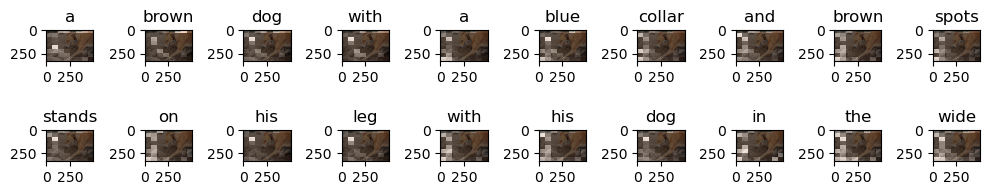

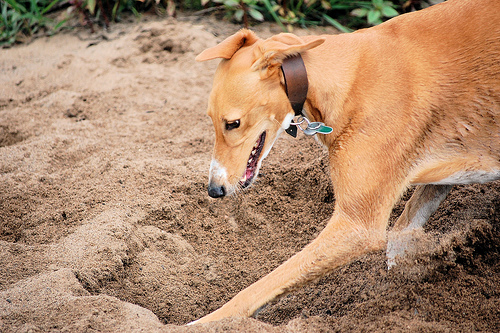

In [76]:
rid=np.random.randint(0,len(img_name_val))
image=img_name_val[rid]
real_caption=' '.join([tokenizer.index_word[i] for i in cap_val[rid] if i not in [0]])
result1,attention_plot=evaluate(image)
print("Real caption:",real_caption)
print("Prediction caption:",' '.join(result1))
plot_attention(image,result1,attention_plot)
Image.open(img_name_val[rid])

In [78]:
%pip install nltk


Note: you may need to restart the kernel to use updated packages.


In [83]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to C:\Users\Pavaki
[nltk_data]     Maithili\AppData\Roaming\nltk_data...


True

In [86]:
idx = 0

prediction, attention_plot = evaluate(img_name_val[idx])

print("Generated output:", prediction)
print("Output type:", type(prediction))

print("\nReference caption:")
print(cap_val[idx])

print("\nImage path:")
print(img_name_val[idx])

Generated output: ['a', 'man', 'and', 'a', 'woman', 'are', 'standing', 'on', 'the', 'shore', 'of', 'a', 'lake', 'and', 'are', 'trying', 'to', 'look', 'over', 'a', 'brown', 'object']
Output type: <class 'list'>

Reference caption:
[   3    2   12    5   26  133  440  597    2  144 1052   38    2  510
   67    4    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0]

Image path:
C:\Users\Pavaki Maithili/Downloads\Flickr8k_Dataset\Flicker8k_Dataset\3606355203_1260f43ec0.jpg


In [122]:
def decode_reference_caption(token_ids):
    words = []

    for token_id in np.array(token_ids).flatten():
        token_id = int(token_id)
        if token_id == 0:
            continue
        word = tokenizer.index_word.get(token_id)

        if word is not None and word not in ["<start>", "<end>", "<pad>"]:
            words.append(word)

    return " ".join(words)
idx = 0

print("Generated caption:")
print(" ".join(evaluate(img_name_val[idx])[0]))

print("\nDecoded reference caption:")
print(decode_reference_caption(cap_val[idx]))

Generated caption:
a man and a woman are standing on the shore of a lake and are trying to look over a brown object

Decoded reference caption:
a man in red swimming trunks pushing a baby stroller down a crowded beach


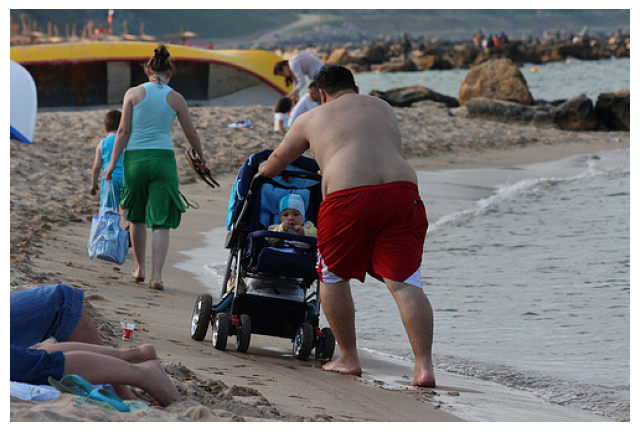

Generated caption:
a man and a woman are standing on the shore of a lake and are trying to look over a brown object

Reference caption:
a man in red swimming trunks pushing a baby stroller down a crowded beach


In [88]:
from PIL import Image
import matplotlib.pyplot as plt

idx = 0

img = Image.open(img_name_val[idx])
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

print("Generated caption:")
print(" ".join(evaluate(img_name_val[idx])[0]))

print("\nReference caption:")
print(decode_reference_caption(cap_val[idx]))

Number of saved loss values: 34391


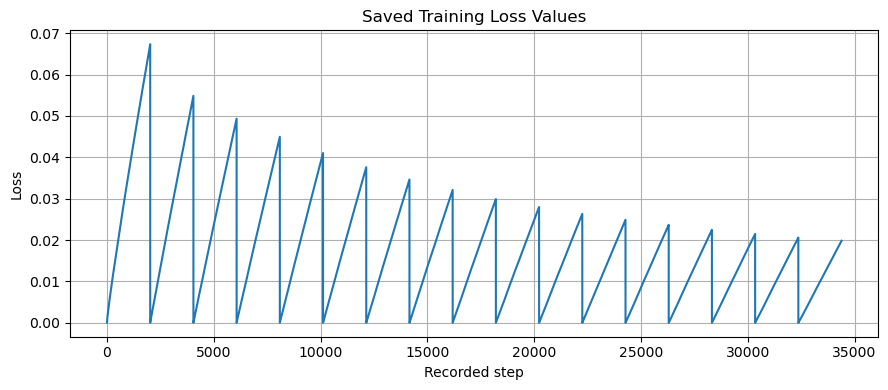

First loss: 9.720688103698194e-05
Last loss: 0.01982777938246727


In [123]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
loss_values = []

for value in loss_plot:
    try:
        loss_values.append(float(value.numpy()))
    except (AttributeError, TypeError, ValueError):
        try:
            loss_values.append(float(value))
        except (TypeError, ValueError):
            continue

print("Number of saved loss values:", len(loss_values))

if loss_values:
    plt.figure(figsize=(9, 4))
    plt.plot(loss_values)
    plt.title("Saved Training Loss Values")
    plt.xlabel("Recorded step")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print("First loss:", loss_values[0])
    print("Last loss:", loss_values[-1])
else:
    print("No numeric loss values could be extracted.")

In [110]:
from collections import Counter

paths = [
    str(p).replace("\\", "/").lower()
    for p in img_name_val
]

counts = Counter(paths)

print("Total validation entries:", len(paths))
print("Unique image paths:", len(set(paths)))
print("Paths appearing more than once:",
      sum(1 for count in counts.values() if count > 1))

print("\nExample duplicate paths:")
for path, count in counts.items():
    if count > 1:
        print(path, "appears", count, "times")
        break

Total validation entries: 8095
Unique image paths: 1619
Paths appearing more than once: 1619

Example duplicate paths:
c:/users/pavaki maithili/downloads/flickr8k_dataset/flicker8k_dataset/3606355203_1260f43ec0.jpg appears 5 times


In [124]:
import numpy as np
import pandas as pd
import re
from collections import defaultdict
from nltk.translate.bleu_score import (
    sentence_bleu,
    SmoothingFunction
)

smooth = SmoothingFunction().method1
def decode_reference_caption(caption):
    words = []

    for token in caption:
        token = int(token)

        if token == 0:
            continue

        word = tokenizer.index_word.get(token, "<unk>")

        if word == "<start>":
            continue

        if word == "<end>":
            break

        if word != "<pad>":
            words.append(word)

    return words


def clean_words(words):
    cleaned = []

    for word in words:
        word = str(word).lower().strip()
        word = re.sub(r"[^a-z0-9'-]", "", word)

        if word and word not in ("<start>", "<end>", "<pad>"):
            cleaned.append(word)

    return cleaned
image_references = defaultdict(list)
image_paths = {}

for image_path, caption in zip(img_name_val, cap_val):

    normalized_path = str(image_path).replace("\\", "/").lower()

    image_paths.setdefault(normalized_path, image_path)

    reference = clean_words(decode_reference_caption(caption))

    if reference:
        image_references[normalized_path].append(reference)


print("Unique validation images:", len(image_paths))
results = []

for count, (normalized_path, image_path) in enumerate(
    image_paths.items(), start=1
):
    try:
        predicted_words, _ = evaluate(image_path)
        predicted_words = clean_words(predicted_words)

        references = image_references[normalized_path]

        if not predicted_words or not references:
            assessment = "Needs Review"
            best_bleu1 = 0.0
            best_bleu2 = 0.0

        else:
            bleu1 = sentence_bleu(
                references,
                predicted_words,
                weights=(1, 0, 0, 0),
                smoothing_function=smooth
            )

            bleu2 = sentence_bleu(
                references,
                predicted_words,
                weights=(0.5, 0.5, 0, 0),
                smoothing_function=smooth
            )

            best_bleu1 = bleu1
            best_bleu2 = bleu2
            if best_bleu1 >= 0.60 and best_bleu2 >= 0.30:
                assessment = "Likely Correct"
            elif best_bleu1 >= 0.30 or best_bleu2 >= 0.15:
                assessment = "Partially Correct"
            else:
                assessment = "Needs Review"

        results.append({
            "image": str(image_path),
            "generated_caption": " ".join(predicted_words),
            "reference_captions": " | ".join(
                " ".join(ref) for ref in references
            ),
            "BLEU-1": round(best_bleu1, 3),
            "BLEU-2": round(best_bleu2, 3),
            "assessment": assessment
        })

        if count % 100 == 0:
            print(f"Evaluated {count}/{len(image_paths)} images")

    except Exception as e:
        print("Error:", image_path, str(e))
results_df = pd.DataFrame(results)

print("\nTotal unique images evaluated:", len(results_df))

print("\nAssessment counts:")
print(results_df["assessment"].value_counts())

print("\nAverage BLEU scores:")
print(results_df[["BLEU-1", "BLEU-2"]].mean())

display(results_df.head(20))

results_df.to_csv(
    "image_caption_evaluation_unique_images.csv",
    index=False
)

print("\nSaved: image_caption_evaluation_unique_images.csv")

Unique validation images: 1619
Evaluated 100/1619 images
Evaluated 200/1619 images
Evaluated 300/1619 images
Evaluated 400/1619 images
Evaluated 500/1619 images
Evaluated 600/1619 images
Evaluated 700/1619 images
Evaluated 800/1619 images
Evaluated 900/1619 images
Evaluated 1000/1619 images
Evaluated 1100/1619 images
Evaluated 1200/1619 images
Evaluated 1300/1619 images
Evaluated 1400/1619 images
Evaluated 1500/1619 images
Evaluated 1600/1619 images

Total unique images evaluated: 1619

Assessment counts:
assessment
Partially Correct    1084
Likely Correct        309
Needs Review          226
Name: count, dtype: int64

Average BLEU scores:
BLEU-1    0.456075
BLEU-2    0.264349
dtype: float64


,image,generated_caption,reference_captions,BLEU-1,BLEU-2,assessment
0,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,a man and a woman are standing on the shore of...,a man in red swimming trunks pushing a baby st...,0.409,0.242,Partially Correct
1,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,a white dog is running along side by another dog,a dog runs toward the camera his unk hanging o...,0.500,0.075,Partially Correct
2,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,a young boy in a red shirt and a white shirt i...,a boy in a sports uniform chasing a soccer bal...,0.450,0.308,Partially Correct
3,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,two people are riding a blue sled in a blue an...,a man in a black outfit is riding a blue snowm...,0.499,0.340,Partially Correct
4,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,a person in a blue jacket and helmet with a sn...,a child in the snow | a child walking in the s...,0.664,0.427,Likely Correct
5,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,a dog carries a small dog stick in its mouth a...,a brown dog is on the ground growling | a dog ...,0.500,0.297,Partially Correct
6,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,a person in a blue and white jacket snowboardi...,a guy snowboarding down a hill | a skier in a ...,0.417,0.195,Partially Correct
7,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,a girl in a red tank top stands in front of a ...,a group of people gather with only their legs ...,0.205,0.073,Needs Review
8,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,a man standing in front of a rock and body of ...,a man is standing on top of rocks overlooking ...,0.667,0.492,Likely Correct
9,C:\Users\Pavaki Maithili/Downloads\Flickr8k_Da...,a group of women in red dresses are holding a ...,a crowd scene with people in yellow and white ...,0.429,0.314,Partially Correct



Saved: image_caption_evaluation_unique_images.csv


Image folder found: C:\Users\Pavaki Maithili\Downloads\Flickr8k_Dataset\Flicker8k_Dataset

Total validation entries: 8095
Unique images with references: 1619
Duplicate captions removed: 4
Evaluated 100 of 1619 images
Evaluated 200 of 1619 images
Evaluated 300 of 1619 images
Evaluated 400 of 1619 images
Evaluated 500 of 1619 images
Evaluated 600 of 1619 images
Evaluated 700 of 1619 images
Evaluated 800 of 1619 images
Evaluated 900 of 1619 images
Evaluated 1000 of 1619 images
Evaluated 1100 of 1619 images
Evaluated 1200 of 1619 images
Evaluated 1300 of 1619 images
Evaluated 1400 of 1619 images
Evaluated 1500 of 1619 images
Evaluated 1600 of 1619 images

Evaluation completed.
Images evaluated: 1619

SAMPLE CAPTION CHECK

Image: 3606355203_1260f43ec0.jpg
Generated: 'a man and a woman are standing on the shore of a lake and are trying to look over a brown object'
References:
 - a man in red swimming trunks pushing a baby stroller down a crowded beach
 - a man pushes a baby in a carriage on 

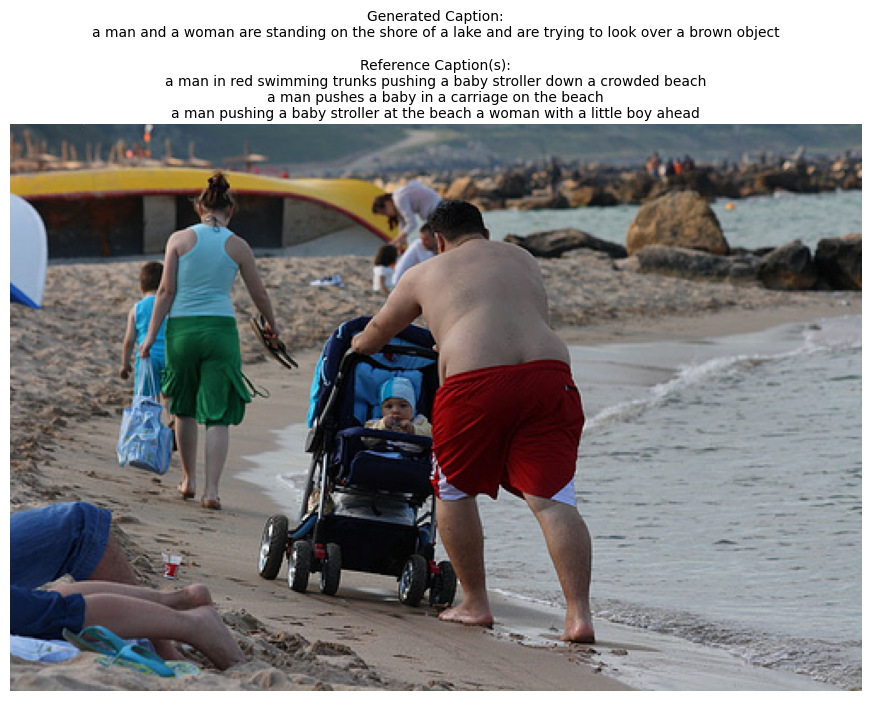

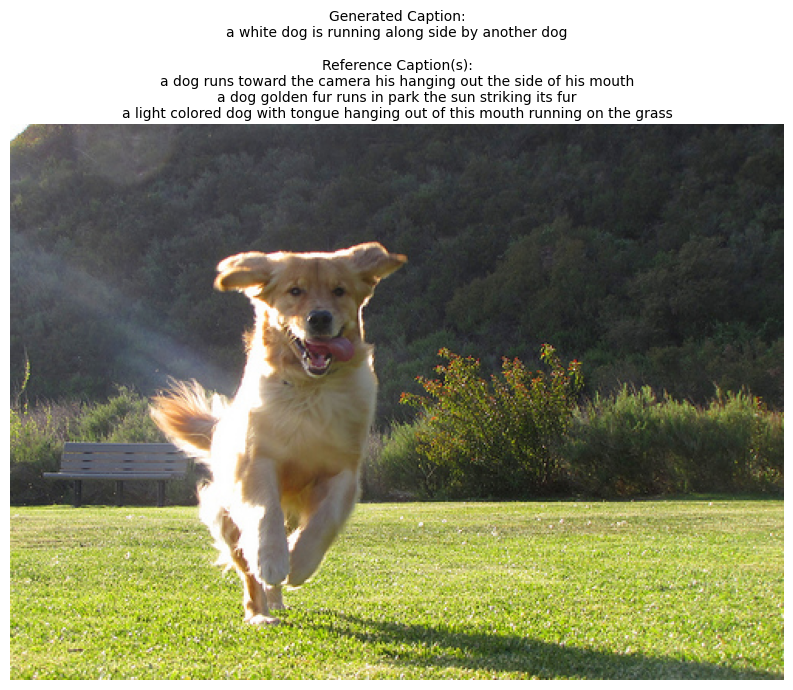

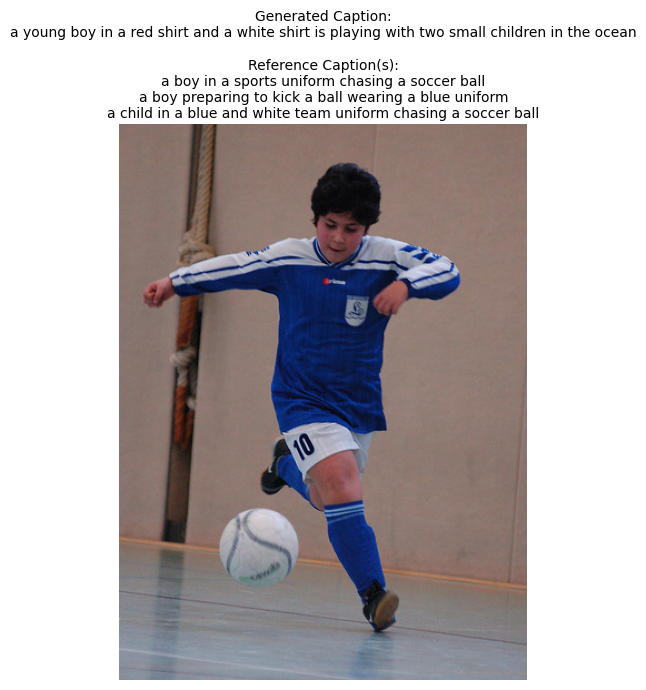

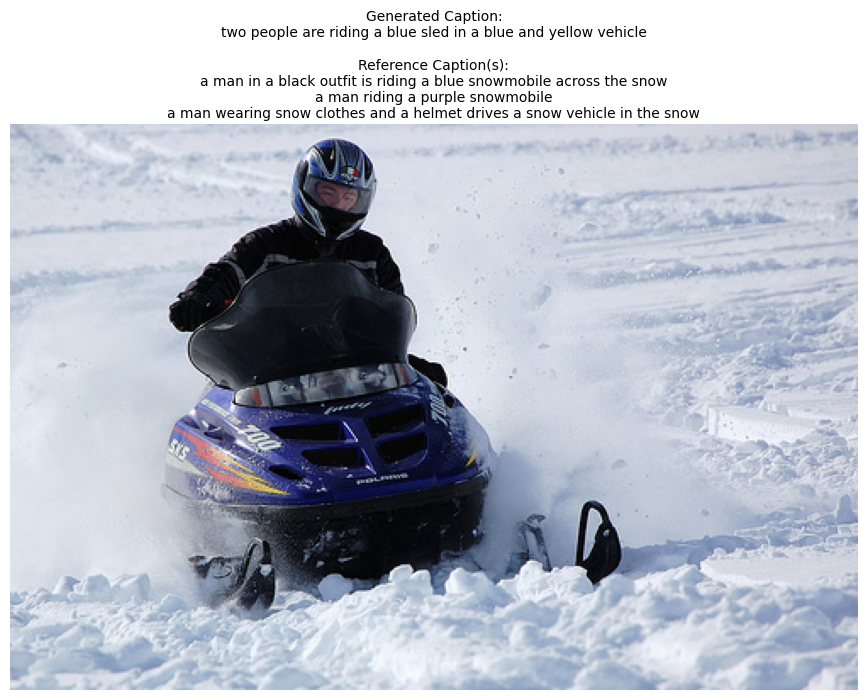

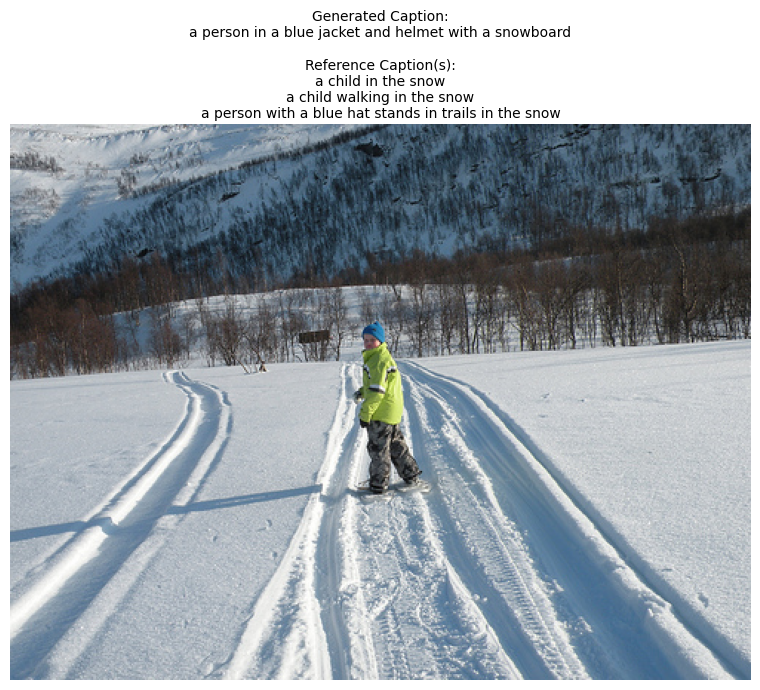


FINAL AVERAGE EVALUATION METRICS
BLEU-1                   : 0.4571 (45.71%)
BLEU-2                   : 0.2651 (26.51%)
BLEU-3                   : 0.1476 (14.76%)
BLEU-4                   : 0.0915 (9.15%)
METEOR                   : 0.3229 (32.29%)
ROUGE-L                  : 0.3511 (35.11%)
Word-level Accuracy      : 0.2606 (26.06%)
Exact Match Accuracy     : 0.0000 (0.00%)
Precision                : 0.3749 (37.49%)
Recall                   : 0.4182 (41.82%)
F1-score                 : 0.3806 (38.06%)


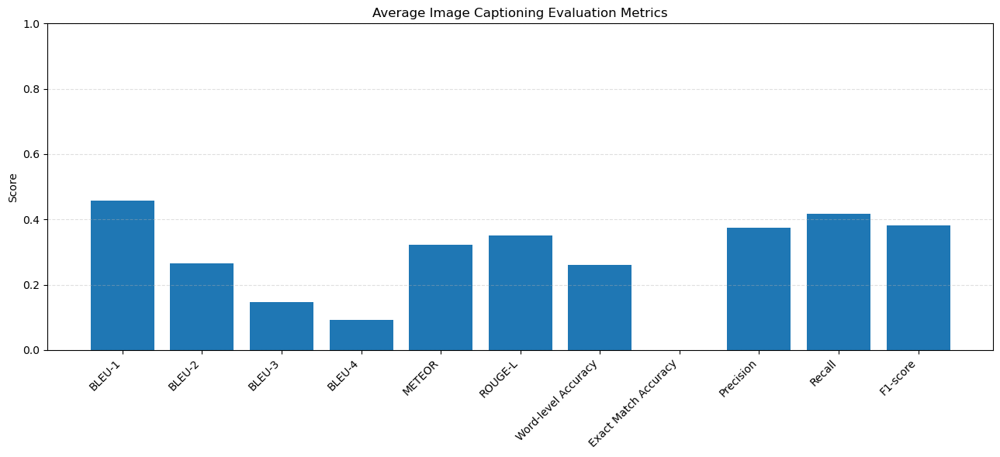

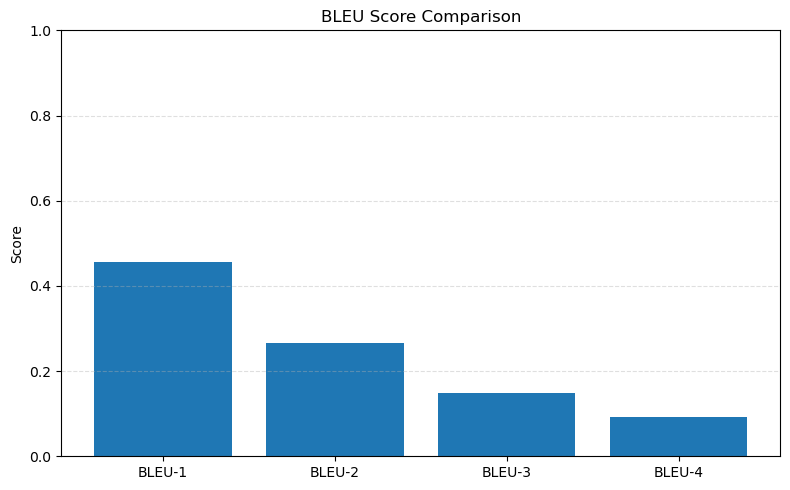

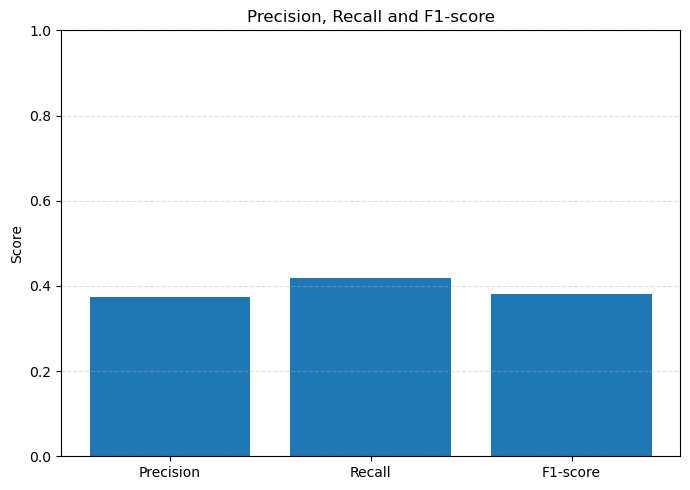

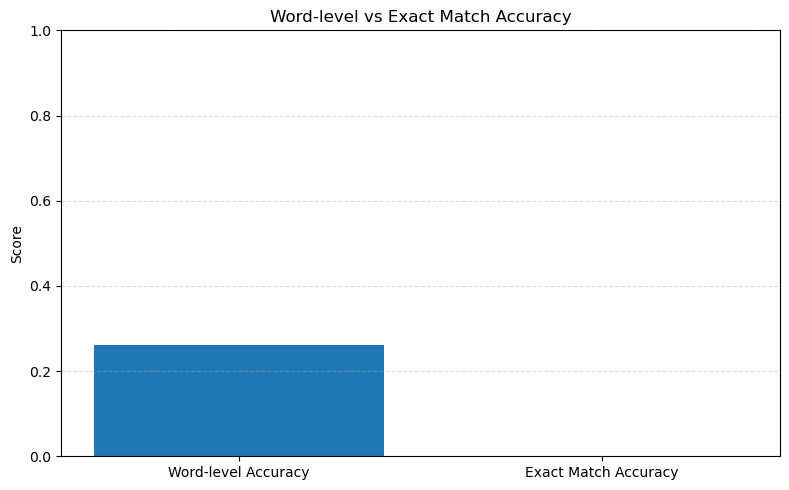


Results saved to:
C:\Users\Pavaki Maithili\flickr8k_caption_evaluation_results.csv

All evaluation steps completed.


In [125]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from collections import Counter, defaultdict
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from nltk.metrics.distance import edit_distance

nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
IMAGE_DIR = r"C:\Users\Pavaki Maithili\Downloads\Flickr8k_Dataset\Flicker8k_Dataset"

if not os.path.isdir(IMAGE_DIR):
    print("WARNING: Image folder not found.")
    print("Current path:", IMAGE_DIR)
    IMAGE_DIR = input("Paste your actual Flickr8k image folder path: ").strip().strip('"')
    if not os.path.isdir(IMAGE_DIR):
        raise FileNotFoundError("Image folder not found. Check the path: " + IMAGE_DIR)

print("Image folder found:", IMAGE_DIR)
start_id = tokenizer.word_index.get("<start>")
end_id = tokenizer.word_index.get("<end>")

if start_id is None:
    start_id = tokenizer.word_index.get("<startseq>")

if end_id is None:
    end_id = tokenizer.word_index.get("<endseq>")

index_word = tokenizer.index_word
def sequence_to_caption(sequence):
    if sequence is None:
        return ""
    if isinstance(sequence, tuple):
        sequence = sequence[0]
    if hasattr(sequence, "numpy"):
        sequence = sequence.numpy()
    if isinstance(sequence, bytes):
        sequence = sequence.decode("utf-8", errors="ignore")
    if isinstance(sequence, str):
        return sequence
    sequence = np.asarray(sequence).reshape(-1).tolist()
    words = []
    for token in sequence:
        try:
            token_id = int(token)
        except (TypeError, ValueError):
            word = str(token).strip()
            if word in ("<start>", "<startseq>"):
                continue
            if word in ("<end>", "<endseq>"):
                break
            if word not in ("<pad>", ""):
                words.append(word)
            continue
        if token_id == 0:
            continue
        if end_id is not None and token_id == end_id:
            break
        if start_id is not None and token_id == start_id:
            continue
        word = index_word.get(token_id)
        if word and word not in ("<start>", "<startseq>", "<end>", "<endseq>", "<pad>"):
            words.append(word)
    return " ".join(words)
def clean_caption(caption):
    text = sequence_to_caption(caption).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return text.split()

def normalize_image_name(image_name):
    if hasattr(image_name, "numpy"):
        image_name = image_name.numpy()
    if isinstance(image_name, bytes):
        image_name = image_name.decode("utf-8", errors="ignore")
    return os.path.basename(str(image_name).strip().strip("'\""))
image_references = defaultdict(list)
duplicate_count = 0

for image_name, caption_entry in zip(img_name_val, cap_val):
    image_key = normalize_image_name(image_name)
    caption_tokens = clean_caption(caption_entry)
    caption_text = " ".join(caption_tokens)
    if not image_key or not caption_text:
        continue
    if caption_text in image_references[image_key]:
        duplicate_count += 1
    else:
        image_references[image_key].append(caption_text)

image_references = {
    image: references
    for image, references in image_references.items()
    if references
}

unique_images = list(image_references.keys())

print("\nTotal validation entries:", len(img_name_val))
print("Unique images with references:", len(unique_images))
print("Duplicate captions removed:", duplicate_count)

if not unique_images:
    raise ValueError("No reference captions found. Check img_name_val and cap_val.")
def resolve_image_path(image_name):
    if os.path.isfile(image_name):
        return image_name
    candidate = os.path.join(
        IMAGE_DIR,
        os.path.basename(image_name)
    )
    if os.path.isfile(candidate):
        return candidate
    raise FileNotFoundError(
        "Image file not found: " + image_name
        + "\nExpected location: " + candidate
    )
def get_predicted_caption(image_path):
    result = evaluate(image_path)
    if isinstance(result, tuple):
        result = result[0]
    return sequence_to_caption(result)
def overlap_scores(reference_tokens, predicted_tokens):
    if not reference_tokens or not predicted_tokens:
        return 0.0, 0.0, 0.0
    reference_counts = Counter(reference_tokens)
    predicted_counts = Counter(predicted_tokens)
    common_words = sum(
        (reference_counts & predicted_counts).values())
    precision = common_words / len(predicted_tokens)
    recall = common_words / len(reference_tokens)
    if precision + recall == 0:
        f1 = 0.0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return precision, recall, f1
def rouge_l_score(reference_tokens, predicted_tokens):
    if not reference_tokens or not predicted_tokens:
        return 0.0
    rows = len(reference_tokens) + 1
    cols = len(predicted_tokens) + 1
    dp = [[0] * cols for _ in range(rows)]
    for i in range(1, rows):
        for j in range(1, cols):
            if reference_tokens[i - 1] == predicted_tokens[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(
                    dp[i - 1][j],
                    dp[i][j - 1])
    lcs = dp[-1][-1]
    precision = lcs / len(predicted_tokens)
    recall = lcs / len(reference_tokens)
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)
def word_accuracy(reference_tokens, predicted_tokens):
    if not reference_tokens and not predicted_tokens:
        return 1.0
    max_length = max(
        len(reference_tokens),len(predicted_tokens))
    if max_length == 0:
        return 1.0
    distance = edit_distance(reference_tokens,predicted_tokens)
    return max(0.0, 1.0 - distance / max_length)
smooth = SmoothingFunction().method1
all_results = []

for number, image_name in enumerate(unique_images, start=1):
    image_path = resolve_image_path(image_name)
    predicted_caption = get_predicted_caption(image_path)
    predicted_tokens = clean_caption(predicted_caption)
    reference_texts = image_references[image_name]
    reference_tokens_list = [
        clean_caption(reference)
        for reference in reference_texts]
    reference_tokens_list = [
        reference
        for reference in reference_tokens_list
        if reference]
    if not reference_tokens_list:
        continue
    scored_references = []
    for reference_tokens in reference_tokens_list:
        _, _, reference_f1 = overlap_scores(
            reference_tokens,
            predicted_tokens)
        scored_references.append((reference_f1, reference_tokens))
    _, best_reference = max(scored_references,key=lambda item: item[0])
    precision, recall, f1 = overlap_scores(best_reference,predicted_tokens)
    bleu_scores = []
    for n in range(1, 5):
        weights = tuple(1.0 / n if index < n else 0.0
                        for index in range(4))
        score = sentence_bleu(reference_tokens_list,predicted_tokens,weights=weights,smoothing_function=smooth)
        bleu_scores.append(score)
    try:
        meteor = meteor_score(references=reference_tokens_list,hypothesis=predicted_tokens)
    except Exception as error:
        print("METEOR error for", image_name, ":", error)
        meteor = 0.0
    rouge_l = max(rouge_l_score(reference, predicted_tokens)
                  for reference in reference_tokens_list)
    word_acc = max(word_accuracy(reference, predicted_tokens)
                   for reference in reference_tokens_list)
    predicted_text = " ".join(predicted_tokens)
    exact_match = float(any(predicted_text == " ".join(reference)
                            for reference in reference_tokens_list))
    all_results.append({
        "Image": image_name,
        "Generated Caption": predicted_text,
        "BLEU-1": bleu_scores[0],
        "BLEU-2": bleu_scores[1],
        "BLEU-3": bleu_scores[2],
        "BLEU-4": bleu_scores[3],
        "METEOR": meteor,
        "ROUGE-L": rouge_l,
        "Word-level Accuracy": word_acc,
        "Exact Match Accuracy": exact_match,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1})
    if number % 100 == 0:
        print("Evaluated", number,"of", len(unique_images), "images")
if not all_results:
    raise ValueError("No images were evaluated. Check evaluate() and dataset variables.")
print("\nEvaluation completed.")
print("Images evaluated:", len(all_results))
print("\nSAMPLE CAPTION CHECK")

for result in all_results[:5]:
    print("\nImage:", result["Image"])
    print("Generated:", repr(result["Generated Caption"]))
    print("References:")
    for reference in image_references[result["Image"]]:
        print(" -", reference)
    print("Precision:", round(result["Precision"], 4))
    print("Recall:", round(result["Recall"], 4))
    print("F1-score:", round(result["F1-score"], 4))
from PIL import Image
import os
import matplotlib.pyplot as plt
for result in all_results[:5]:
    image_name = result["Image"]
    image_path = resolve_image_path(image_name)

    img = Image.open(image_path).convert("RGB")

    plt.figure(figsize=(10, 7))
    plt.imshow(img)
    plt.axis("off")

    generated_caption = result["Generated Caption"]
    reference_captions = image_references[image_name]

    plt.title(
        "Generated Caption:\n"
        + generated_caption
        + "\n\nReference Caption(s):\n"
        + "\n".join(reference_captions[:3]),
        fontsize=10,
        wrap=True
    )

    plt.tight_layout()
    plt.show()
metric_names = [
    "BLEU-1",
    "BLEU-2",
    "BLEU-3",
    "BLEU-4",
    "METEOR",
    "ROUGE-L",
    "Word-level Accuracy",
    "Exact Match Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

mean_metrics = {}

for metric in metric_names:
    mean_metrics[metric] = float(
        np.mean([
            result[metric]
            for result in all_results]))
print("\n" + "=" * 55)
print("FINAL AVERAGE EVALUATION METRICS")
print("=" * 55)

for metric, value in mean_metrics.items():
    print("{:<25}: {:.4f} ({:.2f}%)".format(metric,value,value * 100))
plt.figure(figsize=(13, 6))
plt.bar(list(mean_metrics.keys()),list(mean_metrics.values()))
plt.title("Average Image Captioning Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
bleu_names = [
    "BLEU-1",
    "BLEU-2",
    "BLEU-3",
    "BLEU-4"]

plt.figure(figsize=(8, 5))
plt.bar(bleu_names,[mean_metrics[name] for name in bleu_names])
plt.title("BLEU Score Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
prf_names = [
    "Precision",
    "Recall",
    "F1-score"]

plt.figure(figsize=(7, 5))
plt.bar(prf_names,[mean_metrics[name] for name in prf_names])
plt.title("Precision, Recall and F1-score")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
accuracy_names = [
    "Word-level Accuracy",
    "Exact Match Accuracy"]

plt.figure(figsize=(8, 5))
plt.bar(accuracy_names,[mean_metrics[name] for name in accuracy_names])
plt.title("Word-level vs Exact Match Accuracy")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
results_df = pd.DataFrame(all_results)

output_file = os.path.abspath("flickr8k_caption_evaluation_results.csv")

results_df.to_csv(output_file, index=False)

print("\nResults saved to:")
print(output_file)
print("\nAll evaluation steps completed.")
